# 4. Differentiate and fit through equilibrium

**Goal:** replace lesson 3's fixed pose with a solved displacement $u^*(p)$.
Keep the same Neo-Hookean material and tetrahedral bunny. Clamp the lower part
and fit the displacement of the ears under a prescribed load.

Given a fixed load, native Newton finds the free displacement satisfying
$g_f(u,p)=\partial\Pi/\partial u_f=0$. We fit the two material parameters from
synthetic free-displacement observations.

In [13]:
from pathlib import Path

import numpy as np
import scipy.sparse as sp
import torch
import matplotlib.pyplot as plt
%matplotlib inline
from litepgo import dof, energy, fem, mesh, solver
from litepgo.torch import TorchVolumetricMaterial, response

torch.set_num_threads(1)
dtype = torch.float64

In [14]:
class TorchNeoHookean(TorchVolumetricMaterial):
    num_parameters = 2

    @staticmethod
    def W(F, Fp, theta):
        Fe = F @ torch.linalg.inv(Fp)
        lam, mu = theta.unbind(-1)
        log_J = torch.linalg.det(Fe).log()
        psi = 0.5 * mu * (Fe.square().sum((-2, -1)) - 3) - mu * log_J + 0.5 * lam * log_J.square()
        W = torch.linalg.det(Fp) * psi
        return torch.where((lam >= 0) & (mu > 0), W, torch.full_like(W, float('nan')))

## Boundary conditions and a fixed load

### Keep the tetrahedra that can deform

Compute each vertex's height from its original $y$ coordinate. The lowest
vertex has height 0 and the highest has height 1. Clamp the vertices at or
below height 0.75 and leave the vertices above it free. The threshold is a
fraction of the bunny's height.

`.any(axis=1)` keeps a tetrahedron if at least one of its four vertices is
free. The retained tetrahedron still needs all four vertices, including
any fixed ones. For example, a tetrahedron with three fixed vertices and one
free vertex transfers the clamp's constraint to the moving part of the mesh.

A tetrahedron with four fixed vertices has no dependence on the free
displacement. It contributes zero to the free energy gradient and stiffness,
so leaving it out gives the same free equilibrium equations. `vertices` maps
the retained local vertices back to their original bunny indices.

In [15]:
asset_dir = next((folder for folder in (Path("."), Path("assets"), Path("../../assets"))
                  if (folder / "bunny-tet.veg").is_file()), Path("."))
bunny = mesh.read_veg(asset_dir / "bunny-tet.veg")
y = bunny.positions[:, 1]
bunny_height = (y - y.min()) / np.ptp(y)
cells = bunny.topology.cells
active_cells = cells[(bunny_height[cells] > .75).any(axis=1)]
vertices, local_cells = np.unique(active_cells, return_inverse=True)
X, height = bunny.positions[vertices], bunny_height[vertices]
topology = mesh.TetTopology(len(X), local_cells.reshape(-1, 4).astype(np.int32))
mapping = dof.VertexDofMap(topology, 3)
rest = X.ravel()
geometry = [fem.InterpolatedResponse[fem.TetP1Basis](mapping.gather(e, rest))
            for e in range(topology.num_cells)]
Fp_field = energy.AffineResponse(np.zeros((9, 3)), np.eye(3).ravel(order='F'))
plastic = [Fp_field] * topology.num_cells
key = (TorchNeoHookean, fem.TetP1Basis, fem.TetCentroidQuadrature)
truth = np.array([2., 3.])

### Fix all three displacement components at each clamped vertex

The displacement vector stores $(u_x,u_y,u_z)$ consecutively for every
vertex. `np.repeat(..., 3)` turns a vertex mask into a mask for the three
displacement DOFs. `DofReduction` fixes the selected DOFs at zero, and
Newton starts at zero displacement and updates the free DOFs.

In [16]:
fixed_dofs = np.flatnonzero(np.repeat(height <= .75, 3))
free = np.flatnonzero(np.repeat(height > .75, 3))
fixed = dof.DofReduction(mapping.num_dofs, fixed_dofs.tolist())
initial_u = np.zeros(mapping.num_dofs)
options = solver.NewtonOptions(gradient_tolerance=1e-12, max_iterations=100)
print('Retained tetrahedra:', topology.num_cells)
print('Fixed vertices retained at the clamp:', len(fixed_dofs) // 3)
print('Free vertices / DOFs:', len(free) // 3, len(free))

Retained tetrahedra: 2908
Fixed vertices retained at the clamp: 115
Free vertices / DOFs: 808 2424


### Apply a fixed load to the top surface

Select vertices with height at least 0.85 that also lie on the **original**
bunny surface. This selects the exposed ear region and excludes interior
vertices and any new cut faces. Divide the prescribed total force equally
among the selected vertices. The total stays the same as the parameters
change.

The external potential is $-f^\mathsf{T}u$. `QuadraticEnergy` represents
this linear potential with a zero quadratic matrix and linear coefficient
$-f$. Its gradient is $-f$, so at equilibrium the internal energy gradient
balances the applied load on the free DOFs.

In [17]:
surface = np.asarray(mesh.extract_surface_with_vertices(bunny).vertices)
loaded = np.isin(vertices, surface) & (height >= .85)
assert len(free) > 0 and loaded.any()
load = np.zeros_like(X)
total_load = np.array([.0004, .0016, -.0006])
load[loaded] = total_load / loaded.sum()
external = energy.QuadraticEnergy(sp.csc_matrix((mapping.num_dofs, mapping.num_dofs)), -load.ravel())
np.testing.assert_allclose(load.sum(axis=0), total_load)
print('Loaded surface vertices:', loaded.sum())
print('Total applied force:', load.sum(axis=0))

Loaded surface vertices: 275
Total applied force: [ 0.0004  0.0016 -0.0006]


### Locate the clamp and the load on the bunny

The overview shows the original bunny before clipping. Gray points are fixed,
blue circles are free and unloaded, and red triangles are free and loaded.
The two ear close-ups show the groups separately in the same $x$–$y$ projection
and at the same scale. The dashed line marks 85% of the original height.
Unloaded points above the line are interior vertices. The load is applied
to surface vertices above or on the line.

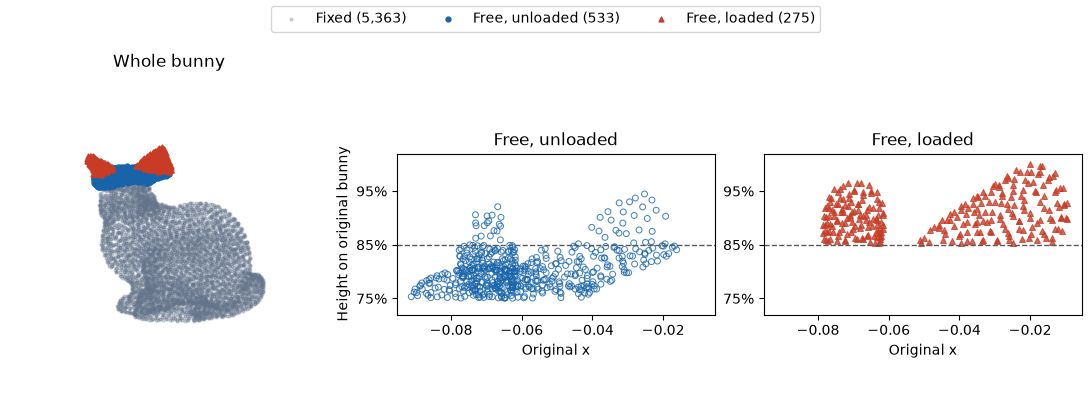

In [18]:
clamped = bunny_height <= .75
loaded_on_bunny = np.zeros(len(bunny_height), dtype=bool)
loaded_on_bunny[vertices[loaded]] = True
assert not np.any(clamped & loaded_on_bunny)
unloaded_free = ~clamped & ~loaded_on_bunny

fig = plt.figure(figsize=(10.8, 4.3), layout='constrained')
overview = fig.add_subplot(131, projection='3d')
unloaded_view = fig.add_subplot(132)
loaded_view = fig.add_subplot(133, sharex=unloaded_view, sharey=unloaded_view)
points = bunny.positions[:, [0, 2, 1]]  # Keep the original y vertical.

overview.scatter(*points[clamped].T, s=4, color='#64748b', alpha=.28,
                 depthshade=False, label=f'Fixed ({clamped.sum():,})')
groups = (
    ('Free, unloaded', unloaded_free, 'o', '#1764ab', unloaded_view),
    ('Free, loaded', loaded_on_bunny, '^', '#c83c26', loaded_view),
)
for label, mask, marker, color, closeup in groups:
    overview.scatter(*points[mask].T, s=12, marker=marker, color=color, depthshade=False,
                     label=f'{label} ({mask.sum():,})')
    facecolor = 'none' if marker == 'o' else color
    closeup.scatter(*bunny.positions[mask, :2].T, s=18, marker=marker,
                    facecolors=facecolor, edgecolors=color, linewidths=.75, alpha=.78)
    closeup.set(title=label, xlabel='Original x', aspect='equal', adjustable='box')

height_ticks = y.min() + np.ptp(y) * np.array([.75, .85, .95])
for ax in (unloaded_view, loaded_view):
    ax.axhline(height_ticks[1], color='0.35', linewidth=1, linestyle='--')
    ax.set_yticks(height_ticks, ['75%', '85%', '95%'])
    ax.set_ylim(y.min() + .72 * np.ptp(y), y.max() + .02 * np.ptp(y))
unloaded_view.set_ylabel('Height on original bunny')

overview.set_title('Whole bunny')
overview.set_box_aspect(np.ptp(points, axis=0))
overview.set_proj_type('ortho')
overview.view_init(elev=12, azim=-65)
overview.set_axis_off()
fig.legend(*overview.get_legend_handles_labels(), loc='outside upper center', ncol=3)
plt.show()

## The two factories must describe the same system

### Fix the material parameters and build the total potential

`make_energy(p)` fixes one trial pair $p=(\lambda,\mu)$. The constant
`AffineResponse` gives every element this pair. The returned energy object
takes a displacement $u$ and evaluates the total potential

$$\Pi(u,p)=E_{\mathrm{int}}(u,p)-f^\mathsf{T}u.$$

`external` already represents $-f^\mathsf{T}u$, so both terms enter
`WeightedSumEnergy` with weight 1. Newton uses the total potential's
displacement gradient and stiffness to find the equilibrium pose for this $p$.

In [ ]:
def make_energy(p, *, load_energy=external):
    theta_field = energy.AffineResponse(A=np.zeros((2, 3)), offset=p)
    elastic = fem.VolumetricFemEnergy[key](
        displacement_map=mapping,
        rest_position_fields=geometry,
        Fp=plastic,
        theta=[theta_field] * topology.num_cells,
    )
    return energy.WeightedSumEnergy(terms=[(elastic, 1.), (load_energy, 1.)])

### Fix the pose and build the material response

`make_response(u)` fixes the displacement. The returned response takes $p$
and gives $g_{\mathrm{int}}(u,p)=\partial E_{\mathrm{int}}/\partial u$, the
same fixed-pose calculation used in lesson 3. `ConstantDofMap` shares the
two parameter entries across all elements.

The total gradient is $g_{\mathrm{tot}}=g_{\mathrm{int}}-f$. At fixed $u$,
the prescribed load $f$ stays constant as $p$ changes, so

$$B=\left.\frac{\partial g_{\mathrm{tot}}}{\partial p}\right|_u
   =\left.\frac{\partial g_{\mathrm{int}}}{\partial p}\right|_u.$$

The internal response therefore gives the parameter derivative needed by
the equilibrium equations. The external term still contributes to the
forward equilibrium solve through `make_energy`.

In [ ]:
parameter_map = dof.ConstantDofMap(topology=topology, num_dofs=2)

def make_response(u):
    return fem.VolumetricFemForceMaterialResponse[key](
        parameter_map=parameter_map,
        displacement_map=mapping,
        rest_position_fields=geometry,
        displacement=u,
        Fp=plastic,
    )

### Give both factories to the equilibrium response

`StaticEquilibriumResponse` maps the two material parameters to the solved
displacement. It uses `make_energy(p)` to find $u^*(p)$ under the clamp and
load. To differentiate that equilibrium, it uses `make_response(u^*)` to
get the parameter sensitivity at the solved pose. The equilibrium equations
use the rows for free displacement DOFs.

Both factories use the same material class, basis, quadrature, geometry, and
plastic field. They also give every element the same global pair $p$. That
keeps the stiffness from the energy and the parameter sensitivity from the
response consistent.

In [ ]:
equilibrium = solver.StaticEquilibriumResponse(
    num_parameters=2,
    fixed=fixed,
    initial=initial_u,
    options=options,
    make_energy=make_energy,
    make_response=make_response,
)

## Define the same kind of outer loss

### Generate the target and set the scale

Solve equilibrium with the reference parameters `truth` to get the target
displacement. Solve again from the initial parameter guess under the same
load and clamp. The root mean square difference between these two
displacements on `free` sets the scale. We keep it fixed throughout fitting,
so the loss at the initial guess is $0.5$ up to numerical rounding.

In [ ]:
target = torch.from_numpy(equilibrium.eval_value(truth).copy())
q_start = torch.tensor(np.log([1.2, 2.0]), dtype=dtype)
q = q_start.clone().requires_grad_()
start = torch.from_numpy(equilibrium.eval_value(q.detach().exp().numpy()).copy())
scale = (start[free] - target[free]).square().mean().sqrt().item()
assert scale > 1e-10

print('max target displacement component:', target[free].abs().max().item())

### Compare the deformed shape vertex by vertex

The predicted and target shapes share the same reference mesh. For a
corresponding vertex with original position $X_a$, its two deformed
positions are $X_a+u_{{\rm pred},a}$ and $X_a+u_{{\rm target},a}$. Their
difference is

$$(X_a+u_{{\rm pred},a})-(X_a+u_{{\rm target},a})
= u_{{\rm pred},a}-u_{{\rm target},a}.$$

The reference position cancels, so comparing the displacements gives
exactly the same residual as comparing the deformed positions. This is a
shape loss with known vertex correspondence. `free` selects all three
coordinates of each free vertex, including free vertices without an
applied nodal force. We divide their residuals by `scale` and take half
the mean squared error.

In [ ]:
def shape_loss(predicted, target, observed, scale):
    residual = (predicted[observed] - target[observed]) / scale
    return 0.5 * residual.square().mean()

def loss(q):
    predicted = response(equilibrium, q.exp())
    return shape_loss(predicted, target, free, scale)

print('initial loss:', loss(q).item())

## What does backward calculate?

### Differentiate the equilibrium equation

Split the displacement into free entries $u_f$ and prescribed entries $u_c$.
Let $g_f$ be the free entries of the total potential gradient. The equilibrium
solution $u_f^*(p)$ satisfies $g_f(u_f^*(p),u_c,p)=0$. The prescribed entries
$u_c$ stay fixed as the material parameters $p$ change.

Differentiate both sides with respect to $p$. The first term comes from the
change in the solved pose. The second comes from changing $p$ at fixed pose.

$$0=\frac{d}{dp}g_f(u_f^*(p),u_c,p)
  =\underbrace{\left.\frac{\partial g_f}{\partial u_f}\right|_p}_{K_{ff}}
   \underbrace{\frac{du_f^*}{dp}}_{S_f}
   +\underbrace{\left.\frac{\partial g_f}{\partial p}\right|_u}_{B_f}.$$

So $K_{ff}S_f=-B_f$. Here $K_{ff}$ is the stiffness restricted to free DOFs,
$B_f$ is the fixed-pose Jacobian from lesson 3 restricted to the same rows,
and $S_f$ is the sensitivity of the solved displacement. For the full
$S_f$, each parameter column is one right-hand side of this system.

For a one-DOF spring with stiffness $k$ and fixed load $f$, the residual is
$g(u,k)=ku-f$. Here $K=k$ and $B=u^*$, so $k\,du^*/dk=-u^*$.
For a positive load, increasing the stiffness decreases the equilibrium
displacement. The displacement change cancels the residual change caused
by changing $k$ at the old pose.

### Use the adjoint to get the scalar loss gradient

This loss depends on $p$ through the solved displacement. Using column
gradients, the chain rule gives $\nabla_p L=S_f^\mathsf{T}\nabla_{u_f}L$.
We only need this product, so solve once for the adjoint vector $a$,

$$K_{ff}^\mathsf{T}a=\nabla_{u_f}L.$$

Substitute this into the chain rule and use the equilibrium derivative,

$$\nabla_p L
= S_f^\mathsf{T}K_{ff}^\mathsf{T}a
= (K_{ff}S_f)^\mathsf{T}a
= -B_f^\mathsf{T}a.$$

`StaticEquilibriumResponse` implements this VJP with the exact, unshifted
stiffness at equilibrium. The current backward call re-solves equilibrium
and differentiates the equation at that state. Torch then applies the
derivative of $p=\exp(q)$ to get $\nabla_q L=p\odot\nabla_p L$.

The central differences below perturb each component of $q$ in both
directions. Every loss evaluation solves equilibrium at the perturbed
parameters, so the check includes the change in the solved displacement.

In [ ]:
analytic = torch.autograd.grad(loss(q), q)[0]
h = 1e-4
numerical = torch.stack([(loss(q.detach() + d) - loss(q.detach() - d)) / (2 * h)
                         for d in h * torch.eye(len(q), dtype=dtype)])
torch.testing.assert_close(analytic, numerical, rtol=2e-4, atol=2e-6)
print('analytic gradient:', analytic.detach().numpy())
print('finite difference:', numerical.detach().numpy())

## Fit and check physical equilibrium

L-BFGS updates the material parameters to match the target displacement. After
fitting, solve equilibrium at the fitted parameters and check the residual on
the free DOFs. This checks that the final shape also balances the applied load.

In [ ]:
def fit(q, loss_fn):
    history = []
    optimizer = torch.optim.LBFGS(
        [q], max_iter=25, tolerance_grad=1e-10,
        tolerance_change=1e-14, line_search_fn='strong_wolfe',
    )

    def closure():
        optimizer.zero_grad()
        value = loss_fn(q)
        value.backward()
        history.append(value.item())
        return value

    optimizer.step(closure)
    return history

before = loss(q).item()
history = fit(q=q, loss_fn=loss)
after = loss(q).item()
assert np.isfinite(after) and after < before * 1e-5
print('loss:', before, '->', after)
print('fitted material parameters:', q.detach().exp().numpy())
fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
ax.semilogy(np.maximum(history, 1e-18), marker='.')
ax.set(xlabel='L-BFGS closure evaluation (includes line-search trials)', ylabel='Loss')
ax.grid(alpha=0.25)
plt.show()
fitted = q.detach().exp().numpy()
state = equilibrium.eval_value(fitted)
residual = make_energy(fitted).eval_gradient(state)[free]
assert np.linalg.norm(residual) < 1e-9
print('free equilibrium residual norm:', np.linalg.norm(residual))

### Compare the target, initial, and fitted shapes

Add each solved displacement to the reference vertex positions $X$. The
left panel shows the full target bunny, with fixed vertices in gray. In
the two close-ups, each hollow circle is a target free vertex and each blue
dot is its predicted counterpart. Both close-ups use the same $x$–$y$
projection and scale.

The RMS position error uses the full three-dimensional distance between
corresponding free vertices, including the coordinate outside the projection.

In [ ]:
def plot_shape_comparison(target_u, predictions):
    target_positions = X + target_u.reshape(-1, 3)
    free_nodes = height > .75
    target_free = target_positions[free_nodes]

    ncols = 1 + len(predictions)
    fig = plt.figure(figsize=(3.5 * ncols, 4.1), layout='constrained')
    overview = fig.add_subplot(1, ncols, 1, projection='3d')
    left_ax = fig.add_subplot(1, ncols, 2)
    comparison_axes = [left_ax] + [
        fig.add_subplot(1, ncols, column, sharex=left_ax, sharey=left_ax)
        for column in range(3, ncols + 1)
    ]

    target_bunny = bunny.positions.copy()
    target_bunny[vertices] = target_positions
    target_view = target_bunny[:, [0, 2, 1]]  # Keep the original y vertical.
    overview.scatter(*target_view[clamped].T, color='#64748b', s=4, alpha=.28, depthshade=False)
    overview.scatter(*target_view[~clamped].T, color='#263746', s=7, depthshade=False)
    overview.set_title('Target · full bunny')
    overview.set_box_aspect(np.ptp(target_view, axis=0))
    overview.set_proj_type('ortho')
    overview.view_init(elev=12, azim=-65)
    overview.set_axis_off()

    for ax, (title, displacement) in zip(comparison_axes, predictions):
        positions = X + displacement.reshape(-1, 3)
        predicted_free = positions[free_nodes]
        rms_error = np.sqrt(np.mean(np.sum((predicted_free - target_free)**2, axis=1)))
        ax.scatter(*target_free[:, :2].T, s=18, facecolors='none', edgecolors='#263746',
                   alpha=.5, linewidths=.65, label='Target')
        ax.scatter(*predicted_free[:, :2].T, s=5, color='#1674b1', alpha=.8, label='Prediction')
        ax.set(title=f'{title}\n3D RMS error: {rms_error:.2e}', xlabel='Deformed x',
               aspect='equal', adjustable='box')
    left_ax.set_ylabel('Deformed y')

    fig.legend(*left_ax.get_legend_handles_labels(), loc='outside upper center', ncol=2)
    plt.show()

plot_shape_comparison(
    target_u=target.numpy(),
    predictions=(('Before fit', start.numpy()), ('After fit', state)),
)

## Try it

1. Swap the $x$ and $y$ components of the total load and regenerate the target
   equilibrium with the reference parameters.
2. Under this same load and target, fit once with all free $x,y,z$ displacement
   components and once with only the free $y$ components. Compare the final
   loss and the recovered $(\lambda,\mu)$ for each fit. How well does the
   $y$-only fit reproduce the full target shape?

### Change the load and regenerate one shared target

Swapping the first two entries of `total_load` preserves its magnitude and
changes its direction. Distribute it over the same surface vertices and
build a new equilibrium response with the same clamp. The energy factory
uses the new constant external potential. The fixed-pose material response
can be reused because the load stays independent of the material parameters.

Generate one target at `truth` and one initial prediction at `q_start`.
Use their full-coordinate RMS discrepancy as a common scale for both fits.

In [ ]:
from functools import partial

turned_total = total_load[[1, 0, 2]]
turned_load = np.zeros_like(X)
turned_load[loaded] = turned_total / loaded.sum()
turned_external = energy.QuadraticEnergy(
    A=sp.csc_matrix((mapping.num_dofs, mapping.num_dofs)),
    b=-turned_load.ravel(),
)
turned_equilibrium = solver.StaticEquilibriumResponse(
    num_parameters=2,
    fixed=fixed,
    initial=initial_u,
    options=options,
    make_energy=partial(make_energy, load_energy=turned_external),
    make_response=make_response,
)

turned_target = torch.from_numpy(turned_equilibrium.eval_value(truth).copy())
turned_start = torch.from_numpy(turned_equilibrium.eval_value(q_start.exp().numpy()).copy())
turned_scale = (turned_start[free] - turned_target[free]).square().mean().sqrt().item()
assert turned_scale > 1e-10
print('New total force:', turned_load.sum(axis=0))

### Fit all coordinates, then fit only the vertical coordinates

The DOFs are stored as $x,y,z$ for each vertex. `free % 3 == 1` selects
the $y$ entries. Both fits use the same L-BFGS settings, starting parameters,
target, and scale. Only the entries passed to the loss change. The equilibrium
response still solves for all three displacement components in both fits.

Report each fit's own initial and final objective. Also evaluate both fitted
shapes using the full $xyz$ loss, so the two final shapes are scored on the
same coordinates. Compare the recovered parameters with the reference pair.

In [ ]:
free_y = free[free % 3 == 1]
assert free_y.size * 3 == free.size

def turned_loss(q, observed):
    predicted = response(turned_equilibrium, q.exp())
    return shape_loss(predicted, turned_target, observed, turned_scale)

turned_predictions = []
print('Reference parameters:', truth)
for label, observed in (('All free xyz', free), ('Free y only', free_y)):
    trial = q_start.clone().requires_grad_()
    loss_fn = partial(turned_loss, observed=observed)
    initial_observed_loss = shape_loss(turned_start, turned_target, observed, turned_scale).item()
    fit(q=trial, loss_fn=loss_fn)

    trial_parameters = trial.detach().exp().numpy()
    predicted = torch.from_numpy(turned_equilibrium.eval_value(trial_parameters).copy())
    turned_predictions.append((label, predicted.numpy()))
    observed_loss = shape_loss(predicted, turned_target, observed, turned_scale).item()
    xyz_loss = shape_loss(predicted, turned_target, free, turned_scale).item()
    assert np.isfinite(observed_loss) and observed_loss < initial_observed_loss
    print(f'{label} ({observed.size:,} entries)')
    print(f'  Observed loss: {initial_observed_loss:.3e} → {observed_loss:.3e}')
    print(f'  Final xyz loss: {xyz_loss:.3e}')
    print(f'  Fitted parameters: {trial_parameters}')

### Overlay the two fits on the new target

The left panel shows the full target bunny under the turned load. The three
close-ups use the same axes to compare the initial prediction and both fitted
predictions. Hollow circles mark the target free vertices, and blue dots mark
the corresponding predicted positions.

The RMS errors in the titles use all three coordinates of all free vertices.
That includes the $x$ and $z$ coordinates that the $y$-only objective did
not observe.

In [ ]:
plot_shape_comparison(
    target_u=turned_target.numpy(),
    predictions=(('Initial (before fit)', turned_start.numpy()), *turned_predictions),
)

**Checkpoint** You can distinguish a fixed-pose material partial derivative
from a total derivative through equilibrium. Next, replace the density with
a small neural correction.